Import the necessary packages

In [1]:
import numpy as np
import polars as pl
import networkx as nx
import matplotlib.pyplot as plt
import pickle                       # standard library, no install needed
from pathlib import Path            # standard library, no install needed

Load the Networks that are Constructed Using Only the 69 Students in All Three Data Sets

In [2]:
# ===== S1: load the shared networks =====
import pickle
from pathlib import Path

def load(path):
    with Path(path).open("rb") as f:                    # open the pickle file
        return pickle.load(f)                           # return whatever object is stored

shared_temporal        = load("../Data/Cleaned/shared_temporal_networks.pkl")
G_friendship_shared    = load("../Data/Cleaned/shared_students_friendship_network.pkl")
G_contact_diary_shared = load("../Data/Cleaned/shared_students_contact_diary_network.pkl")

# for name, obj in [("temporal", shared_temporal), ("friendship", G_friendship_shared), ("diary", G_contact_diary_shared)]:
#     print(name, "->", type(obj))                        # what kind of object is it?
#     if isinstance(obj, dict):                           # if it is a dictionary, show its keys
#         print("   n keys:", len(obj), "| first keys:", list(obj.keys())[:3])

Verify that the network cleaning was done correctly, to only include students that are in all three networks

In [4]:
# FRIEND_KEY = None                                       # e.g. "friendship" if S1 shows a dict of networks
# DIARY_KEY  = None                                       # e.g. "contact_diary"
# G_friend = G_friendship_shared if FRIEND_KEY is None else G_friendship_shared[FRIEND_KEY]   # friendship network
# G_diary  = G_contact_diary_shared if DIARY_KEY is None else G_contact_diary_shared[DIARY_KEY]   # contact-diary network
# networks_by_time = shared_temporal                      # temporal network of the shared students

# give these networks a shorter name
G_friend = G_friendship_shared
G_diary  = G_contact_diary_shared
networks_by_time = shared_temporal

# finds the all of the students that appear in the temporal networks sensor data
temporal_nodes = set().union(*[set(G.nodes) for G in networks_by_time.values()])   
# prints the number of nodes in each network; we expect each to be the same as the total number of students
print(len(temporal_nodes), G_friend.number_of_nodes(), G_diary.number_of_nodes())  
# now, also want to ensure the student identities are the same, not just the same number of students 
print("same students in all three:", temporal_nodes == set(G_friend.nodes) == set(G_diary.nodes)) # if it prints True, then the networks contain all the same student IDs
# verifying that both the friendship and contact diary networks are directed
print(type(G_friend), type(G_diary))                    

69 69 69
same students in all three: True
<class 'networkx.classes.digraph.DiGraph'> <class 'networkx.classes.digraph.DiGraph'>


In [5]:
# ===== Cell 1 (re-run): parameters. BETA is a placeholder until S3 =====
DT = 24 * 3600                                # infectious period: 24 h in seconds
BETA = 0.1                                   # placeholder; recalibrate in S3 (69 students = fewer contacts)
N_REPS = 100                                  # simulations per strategy + coverage
COVERAGES = [0.1, 0.2, 0.3, 0.4, 0.5]         # share of students immunized
rng = np.random.default_rng(42)               # fixed seed = repeatable results

In [6]:
# ===== Cell 2 (REPLACE): student list + arrays, now from the shared networks =====
ids = np.array(sorted(set().union(*[set(G.nodes) for G in networks_by_time.values()], G_friend.nodes, G_diary.nodes)))   # all shared students
N = len(ids)                                  # should be 69

ts = np.array(sorted(t for t, G in networks_by_time.items() if G.number_of_edges() > 0))   # time stamps with >= 1 contact
t_list, i_list, j_list = [], [], []
for t in ts:                                  # time stamps in order
    for u, v in networks_by_time[t].edges():  # each contact at that time
        t_list.append(t); i_list.append(u); j_list.append(v)

t_arr = np.array(t_list)                      # time of each contact
i_arr = np.searchsorted(ids, i_list)          # student 1 as index 0..N-1
j_arr = np.searchsorted(ids, j_list)          # student 2 as index 0..N-1
bounds = np.append(np.searchsorted(t_arr, ts), len(t_arr))   # contacts at ts[k] = rows bounds[k]:bounds[k+1]
print("students:", N, "| time stamps:", len(ts), "| contacts:", len(t_arr))

students: 69 | time stamps: 6814 | contacts: 26060


In [7]:
# ===== Cell 3 (REPLACE): temporal degree =====
deg = np.bincount(i_arr, minlength=N) + np.bincount(j_arr, minlength=N)   # total contacts per student
temporal_degree = deg / len(ts)               # average contacts per time stamp
print("students with no contacts:", int((deg == 0).sum()))   # should be 0 or very few

students with no contacts: 0


In [8]:
def sir(immune, seed, k0, beta, dt, rng, horizon=np.inf):
    """One outbreak. immune = student indices; seed = student index; k0 = start time-stamp index;
    horizon = max seconds the outbreak may run (inf = no limit). Returns # students infected (seed included)."""
    inf = np.full(N, np.inf)          # infection time per student (inf = never infected)
    blocked = np.zeros(N, bool)         # True = immunized
    blocked[np.asarray(immune, dtype=int)] = True   # mark immunized students
    inf[seed] = ts[k0] - 20           # seed infected one step before start (can spread immediately)
    last = ts[k0]               # time of most recent infection
    for k in range(k0, len(ts)):         # replay time stamps in order
        t = ts[k]                  # current time
        if t - last > dt or t - ts[k0] > horizon:   # nobody infectious (>24 h) OR time limit reached
            break                    # outbreak over
        a = i_arr[bounds[k]:bounds[k+1]]      # student 1 of each contact now
        b = j_arr[bounds[k]:bounds[k+1]]      # student 2 of each contact now
        new = []                  # newly infected this step
        for u, v in ((a, b), (b, a)):         # check both directions
            can_pass = (inf[u] < t) & (t - inf[u] <= dt)       # u infectious (infected, <24 h ago)
            can_catch = np.isinf(inf[v]) & ~blocked[v]         # v susceptible (never infected, not immune)
            hit = can_pass & can_catch & (rng.random(len(u)) < beta)   # roll the transmission chance
            new.append(v[hit])                # save who got infected
        new = np.unique(np.concatenate(new))  # combine, remove repeats
        if len(new):           # anyone newly infected?
            inf[new] = t              # record infection time (after loop: no chaining in one step)
            last = t           # update last infection time
    return int(np.isfinite(inf).sum())     # count of infected students

In [9]:
DAY1_END = np.searchsorted(ts, ts[0] + 24*3600)   # index where day 1 ends (seeds start in day 1)

def draw_start_and_seed(immune, rng):
    while True:                               # retry until valid
        k0 = rng.integers(0, DAY1_END)        # random start time on day 1
        present = np.unique(np.r_[i_arr[bounds[k0]:bounds[k0+1]], j_arr[bounds[k0]:bounds[k0+1]]])   # students in contact now
        candidates = np.setdiff1d(present, immune)   # remove immunized students
        if len(candidates):                   # anyone left?
            return k0, rng.choice(candidates) # random seed from them

In [10]:
# ===== S3: re-calibrate BETA for the 69-student network (fewer contacts -> need a larger beta) =====
for b in [0.02, 0.05, 0.1, 0.2, 0.4]:         # candidate transmission chances
    sizes = []
    for _ in range(50):                       # 50 runs each, no immunization
        k0, s = draw_start_and_seed([], rng)
        sizes.append(sir([], s, k0, b, DT, rng))
    print(b, "mean share infected:", round(np.mean(sizes) / N, 2))   # want ~0.3 to 0.5
# -> set BETA in Cell 1 to the first value that lands in that range, then re-run Cell 1

0.02 mean share infected: 0.09
0.05 mean share infected: 0.21
0.1 mean share infected: 0.31
0.2 mean share infected: 0.63
0.4 mean share infected: 0.81


In [11]:
# ===== Cell 6: reachability function =====
ev_k = np.repeat(np.arange(len(ts)), np.diff(bounds))   # time-stamp index of each contact row

def compute_reachability(horizon, n_starts, rng):
    score = np.zeros(N)                                 # one score per student
    for n in range(N):                                  # every student
        rows_n = np.where((i_arr == n) | (j_arr == n))[0]   # contact rows involving student n
        starts = np.unique(ev_k[rows_n])                # time stamps where they have a contact
        starts = starts[starts < DAY1_END]              # day 1 only
        if len(starts) == 0:                            # no contact on day 1: score stays 0
            continue
        chosen = rng.choice(starts, min(n_starts, len(starts)), replace=False)   # random start times
        score[n] = np.mean([sir([], n, k, 1.0, DT, rng, horizon=horizon) - 1 for k in chosen])   # avg # reached (beta = 1)
    return score

In [12]:
# ===== Cell 7: horizon scan (look at the output, then choose HORIZON_HOURS in Cell 8) =====
scan = {}                                               # horizon (hours) -> scores
for hours in [0.5, 1, 2, 4, 8]:                         # horizons to try
    r = compute_reachability(hours * 3600, 2, rng)      # 2 start times per student keeps it quick
    scan[hours] = r                                     # save scores
    print(f"{hours} h: min/median/max = {r.min():.0f} / {np.median(r):.0f} / {r.max():.0f}, "
          f"distinct = {len(np.unique(r.round(1)))}")   # spread of scores (want wide spread, many distinct)

0.5 h: min/median/max = 0 / 3 / 14, distinct = 21
1 h: min/median/max = 0 / 6 / 17, distinct = 28
2 h: min/median/max = 0 / 10 / 21, distinct = 33
4 h: min/median/max = 0 / 21 / 48, distinct = 43
8 h: min/median/max = 0 / 29 / 60, distinct = 49


In [13]:
# ===== Cell 8: final reachability scores =====
HORIZON_HOURS = 4                                      # horizon chose from the scan
reachability = compute_reachability(HORIZON_HOURS * 3600, 5, rng)   # 5 start times averaged per student
print("min / median / max:", reachability.min(), np.median(reachability), reachability.max())

min / median / max: 0.0 18.6 35.666666666666664


In [14]:
# ===== Cell 9: baseline (no immunization) =====
baseline = []                                 # epidemic size from each run
for _ in range(N_REPS):                       # 100 runs
    k0, s = draw_start_and_seed([], rng)      # random day-1 start time + seed (nobody immune)
    baseline.append(sir([], s, k0, BETA, DT, rng))   # run outbreak, save # infected
print("baseline mean share infected:", round(np.mean(baseline) / N, 2))   # avg outbreak / number of students

baseline mean share infected: 0.34


In [15]:
# ===== S4: scores for every targeting measure =====
idx = {s: k for k, s in enumerate(ids)}                 # student ID -> index

def to_array(d):                                        # {student: value} -> array in ids order
    arr = np.zeros(N)                                   # students missing from d get 0
    for s, v in d.items():
        arr[idx[s]] = v
    return arr

measures = {                                            # name -> one score per student
    "temporal_degree":    temporal_degree,
    "reachability":       reachability,
    "diary_degree":       to_array(dict(G_diary.degree())),              # in + out reports (directed)
    "diary_betweenness":  to_array(nx.betweenness_centrality(G_diary)),
    "friend_degree":      to_array(dict(G_friend.degree())),
    "friend_betweenness": to_array(nx.betweenness_centrality(G_friend)),
}
strategies = ["random"] + list(measures)                # all strategies to simulate

In [16]:
# ===== S5: ranking tables =====
rank_table = pl.DataFrame({"student": ids, **measures})   # one row per student
for m in measures:                                      # add a rank column per measure (1 = highest)
    rank_table = rank_table.with_columns(pl.col(m).rank("min", descending=True).alias(m + "_rank"))
rank_table.write_csv("student_rankings.csv")            # save for the repo

# top 10 students by each measure, side by side
top10 = pl.DataFrame({m: ids[np.argsort(-v, kind="stable")][:10] for m, v in measures.items()})
top10 = top10.with_row_index("rank", offset=1)
print(top10)

# how similar are the rankings? (correlation of ranks, 1 = same order)
rank_cols = [m + "_rank" for m in measures]
corr = np.corrcoef(rank_table.select(rank_cols).to_numpy().T)
print(pl.DataFrame(corr.round(2), schema=list(measures)).with_columns(pl.Series("measure", list(measures))))

shape: (10, 7)
┌──────┬───────────────┬──────────────┬──────────────┬───────────────┬──────────────┬──────────────┐
│ rank ┆ temporal_degr ┆ reachability ┆ diary_degree ┆ diary_between ┆ friend_degre ┆ friend_betwe │
│ ---  ┆ ee            ┆ ---          ┆ ---          ┆ ness          ┆ e            ┆ enness       │
│ u32  ┆ ---           ┆ i64          ┆ i64          ┆ ---           ┆ ---          ┆ ---          │
│      ┆ i64           ┆              ┆              ┆ i64           ┆ i64          ┆ i64          │
╞══════╪═══════════════╪══════════════╪══════════════╪═══════════════╪══════════════╪══════════════╡
│ 1    ┆ 255           ┆ 587          ┆ 502          ┆ 364           ┆ 691          ┆ 441          │
│ 2    ┆ 122           ┆ 1485         ┆ 407          ┆ 268           ┆ 642          ┆ 601          │
│ 3    ┆ 275           ┆ 159          ┆ 691          ┆ 502           ┆ 869          ┆ 272          │
│ 4    ┆ 211           ┆ 407          ┆ 468          ┆ 45            ┆ 151  

In [17]:
# ===== S6: simulations for all strategies =====
def top_k(scores, k, rng):
    perm = rng.permutation(N)                           # shuffle (random tie-breaking)
    return perm[np.argsort(-scores[perm], kind="stable")][:k]   # sort high to low, keep first k

rows = []                                               # one row per simulation
for cov in COVERAGES:                                   # 10% ... 50%
    k = int(round(cov * N))                             # number of students to immunize
    for strat in strategies:                            # each strategy
        for rep in range(N_REPS):                       # repeated runs
            if strat == "random":
                immune = rng.choice(N, k, replace=False)        # new random set each run
            else:
                immune = top_k(measures[strat], k, rng)         # top-k by this measure
            k0, s = draw_start_and_seed(immune, rng)            # start time + seed (not immune)
            rows.append((strat, cov, rep, sir(immune, s, k0, BETA, DT, rng)))   # outbreak size

results = pl.DataFrame(rows, schema=["strategy", "coverage", "rep", "size"], orient="row")
results.write_csv("simulation_results.csv")             # save every run for the repo

summary = (results.group_by(["strategy", "coverage"])
           .agg(mean=pl.col("size").mean(), sd=pl.col("size").std(), median=pl.col("size").median())
           .with_columns((1.96 * pl.col("sd") / np.sqrt(N_REPS)).alias("ci95"))   # 95% CI half-width
           .sort(["strategy", "coverage"]))
print(summary.pivot(on="coverage", index="strategy", values="mean").sort("strategy"))   # mean outbreak size table

shape: (7, 6)
┌────────────────────┬───────┬───────┬───────┬──────┬──────┐
│ strategy           ┆ 0.1   ┆ 0.2   ┆ 0.3   ┆ 0.4  ┆ 0.5  │
│ ---                ┆ ---   ┆ ---   ┆ ---   ┆ ---  ┆ ---  │
│ str                ┆ f64   ┆ f64   ┆ f64   ┆ f64  ┆ f64  │
╞════════════════════╪═══════╪═══════╪═══════╪══════╪══════╡
│ diary_betweenness  ┆ 17.9  ┆ 10.96 ┆ 7.25  ┆ 4.05 ┆ 2.78 │
│ diary_degree       ┆ 18.26 ┆ 10.08 ┆ 5.65  ┆ 4.31 ┆ 3.93 │
│ friend_betweenness ┆ 18.47 ┆ 9.23  ┆ 6.64  ┆ 4.21 ┆ 2.7  │
│ friend_degree      ┆ 14.85 ┆ 11.51 ┆ 6.34  ┆ 4.07 ┆ 3.19 │
│ random             ┆ 19.2  ┆ 12.09 ┆ 10.44 ┆ 7.14 ┆ 4.58 │
│ reachability       ┆ 20.65 ┆ 11.87 ┆ 9.47  ┆ 6.43 ┆ 2.83 │
│ temporal_degree    ┆ 20.74 ┆ 8.89  ┆ 6.83  ┆ 4.58 ┆ 2.58 │
└────────────────────┴───────┴───────┴───────┴──────┴──────┘


In [18]:
# ===== S7: Jaccard overlap between selected groups =====
def jaccard(a, b):
    a, b = set(a), set(b)                               # selected students as sets
    return len(a & b) / len(a | b)                      # shared / total unique

names = list(measures)                                  # targeted strategies
N_TIE_DRAWS = 50                                        # average over random tie-breaks
jac = {}                                                # coverage -> matrix of mean Jaccard
for cov in COVERAGES:
    k = int(round(cov * N))
    M = np.zeros((len(names), len(names)))
    for _ in range(N_TIE_DRAWS):
        sets = [top_k(measures[m], k, rng) for m in names]     # one selection per measure
        for a in range(len(names)):
            for b in range(len(names)):
                M[a, b] += jaccard(sets[a], sets[b])
    jac[cov] = M / N_TIE_DRAWS

def jaccard_random(k):                                  # expected Jaccard of two random groups of size k
    overlap = k * k / N                                 # expected shared students
    return overlap / (2 * k - overlap)

# table: Jaccard of each measure with temporal degree, by coverage
jt = pl.DataFrame({"coverage": COVERAGES,
                   **{m: [jac[c][names.index("temporal_degree"), names.index(m)] for c in COVERAGES] for m in names},
                   "two_random_groups": [jaccard_random(int(round(c * N))) for c in COVERAGES]})
print(jt.with_columns(pl.all().exclude("coverage").round(2)))

shape: (5, 8)
┌──────────┬────────────┬────────────┬────────────┬────────────┬───────────┬───────────┬───────────┐
│ coverage ┆ temporal_d ┆ reachabili ┆ diary_degr ┆ diary_betw ┆ friend_de ┆ friend_be ┆ two_rando │
│ ---      ┆ egree      ┆ ty         ┆ ee         ┆ eenness    ┆ gree      ┆ tweenness ┆ m_groups  │
│ f64      ┆ ---        ┆ ---        ┆ ---        ┆ ---        ┆ ---       ┆ ---       ┆ ---       │
│          ┆ f64        ┆ f64        ┆ f64        ┆ f64        ┆ f64       ┆ f64       ┆ f64       │
╞══════════╪════════════╪════════════╪════════════╪════════════╪═══════════╪═══════════╪═══════════╡
│ 0.1      ┆ 1.0        ┆ 0.0        ┆ 0.0        ┆ 0.0        ┆ 0.0       ┆ 0.0       ┆ 0.05      │
│ 0.2      ┆ 1.0        ┆ 0.17       ┆ 0.07       ┆ 0.12       ┆ 0.13      ┆ 0.12      ┆ 0.11      │
│ 0.3      ┆ 1.0        ┆ 0.17       ┆ 0.26       ┆ 0.2        ┆ 0.31      ┆ 0.21      ┆ 0.18      │
│ 0.4      ┆ 1.0        ┆ 0.22       ┆ 0.31       ┆ 0.24       ┆ 0.35      ┆ 

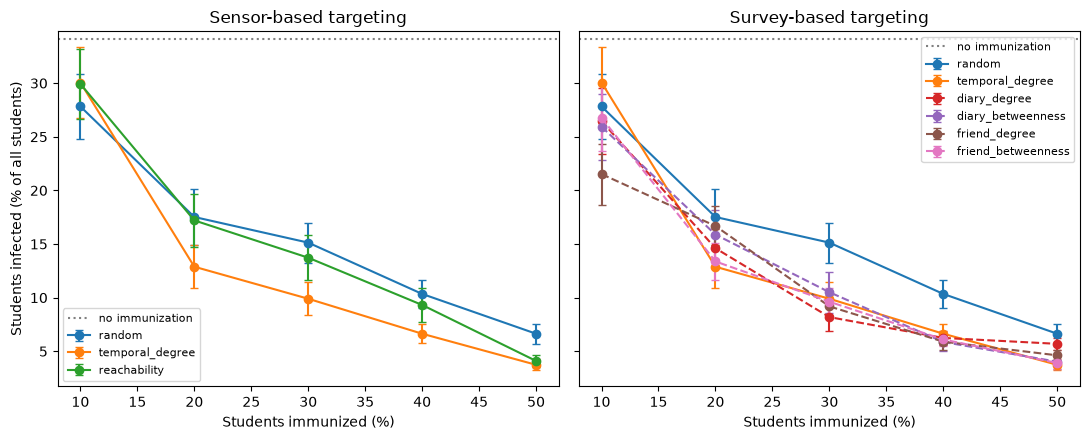

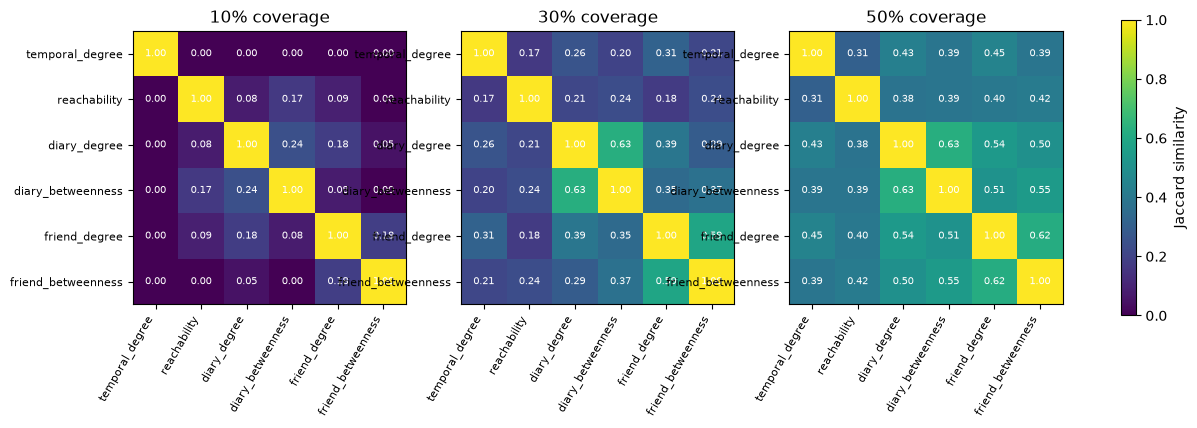

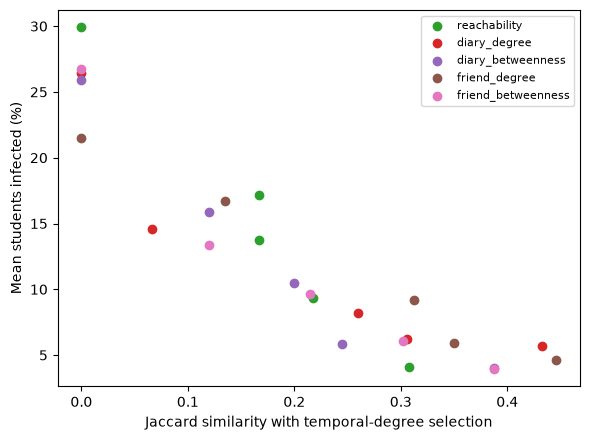

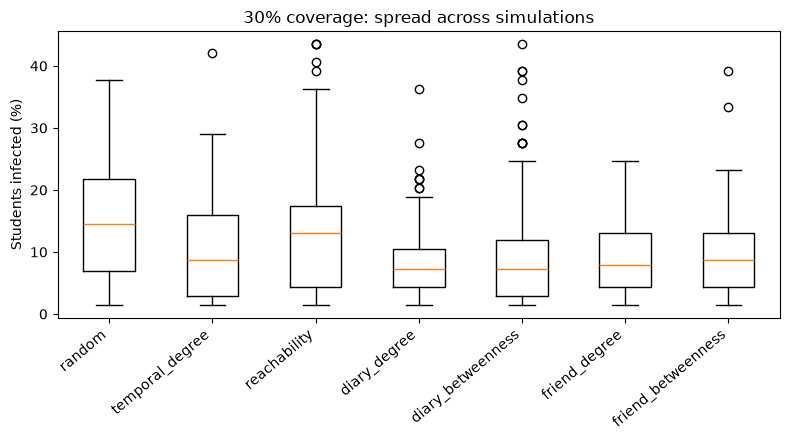

In [19]:
# ===== S8: figures =====
Path("figures").mkdir(exist_ok=True)                    # output folder
colors = dict(zip(strategies, plt.cm.tab10.colors))     # one color per strategy
base_pct = np.mean(baseline) / N * 100                  # no-immunization level (%)

def line(ax, strat, **kw):
    s = summary.filter(pl.col("strategy") == strat)
    ax.errorbar(s["coverage"].to_numpy() * 100, s["mean"].to_numpy() / N * 100,
                yerr=s["ci95"].to_numpy() / N * 100, marker="o", capsize=3, color=colors[strat], label=strat, **kw)

# Figure 1: outbreak size by strategy (left: sensor-based, right: survey-based)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for strat in ["random", "temporal_degree", "reachability"]:
    line(axes[0], strat)
for strat in ["random", "temporal_degree", "diary_degree", "diary_betweenness", "friend_degree", "friend_betweenness"]:
    line(axes[1], strat, ls="--" if strat.startswith(("diary", "friend")) else "-")
for ax, title in zip(axes, ["Sensor-based targeting", "Survey-based targeting"]):
    ax.axhline(base_pct, ls=":", color="gray", label="no immunization")
    ax.set_title(title); ax.set_xlabel("Students immunized (%)"); ax.legend(fontsize=8)
axes[0].set_ylabel("Students infected (% of all students)")
plt.tight_layout(); plt.savefig("figures/fig1_outbreak_size.png", dpi=300); plt.show()

# Figure 2: Jaccard heatmaps at three coverage levels
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, cov in zip(axes, [0.1, 0.3, 0.5]):
    im = ax.imshow(jac[cov], vmin=0, vmax=1, cmap="viridis")
    ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(len(names))); ax.set_yticklabels(names, fontsize=8)
    ax.set_title(f"{int(cov * 100)}% coverage")
    for a in range(len(names)):
        for b in range(len(names)):
            ax.text(b, a, f"{jac[cov][a, b]:.2f}", ha="center", va="center", color="w", fontsize=7)
fig.colorbar(im, ax=axes, shrink=0.8, label="Jaccard similarity")
plt.savefig("figures/fig2_jaccard.png", dpi=300, bbox_inches="tight"); plt.show()

# Figure 3: does overlap with temporal degree go with smaller outbreaks?
plt.figure(figsize=(6, 4.5))
ti = names.index("temporal_degree")
for m in names:
    if m == "temporal_degree":
        continue
    x = [jac[c][ti, names.index(m)] for c in COVERAGES]                                    # Jaccard with temporal degree
    y = [summary.filter((pl.col("strategy") == m) & (pl.col("coverage") == c))["mean"][0] / N * 100 for c in COVERAGES]
    plt.scatter(x, y, color=colors[m], label=m)
plt.xlabel("Jaccard similarity with temporal-degree selection")
plt.ylabel("Mean students infected (%)")
plt.legend(fontsize=8); plt.tight_layout(); plt.savefig("figures/fig3_overlap_vs_size.png", dpi=300); plt.show()

# Figure 4: spread of outbreak sizes at 30% coverage
sub = results.filter(pl.col("coverage") == 0.3)
plt.figure(figsize=(8, 4.5))
plt.boxplot([sub.filter(pl.col("strategy") == s)["size"].to_numpy() / N * 100 for s in strategies])   # one box per strategy
plt.xticks(range(1, len(strategies) + 1), strategies, rotation=40, ha="right"); plt.ylabel("Students infected (%)"); plt.title("30% coverage: spread across simulations")
plt.tight_layout(); plt.savefig("figures/fig4_distribution.png", dpi=300); plt.show()